# 03 — Features, natural relationships and transformations

We now construct the daily feature panel from the original covariates and explain what each feature family contributes to the selected median-relative log target. The construction below reproduces the existing enriched-panel SQL. Its historical windows, point-in-time joins and missing values remain visible.

This notebook finishes **Checkpoint 1**. The next stage will compare ridge specifications and global versus segmented models after review.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


## Feature families and their information times

| Family | Raw inputs and derived features | Economic or statistical motivation |
| --- | --- | --- |
| Auction history | Previous auction, rolling medians, means, dispersion, auction share and spike flags | Persistence, recent shocks and stock-specific auction scale |
| Liquidity | Volume, dollars, turnover, Amihud measure, quoted spread and high–low range | Available activity and trading frictions |
| Returns and price | Lagged returns, momentum, volatility, overnight gap and price | Recent movement and variability |
| Size and history | Lagged market cap, shares, coverage counts and cross-sectional percentiles | Stock scale, short histories and potential segment differences |
| Market and sector | Lagged activity, return, dispersion and breadth | Shared trading conditions |
| Calendar | Month-end, quarter-end, expiry and early-close indicators | Predictable differences in auction participation |
| Security and actions | Point-in-time industry and lagged dividend or distribution flags | Classification and recorded corporate events |

A calendar date can be known before the forecast. A stock or market observation must be available by the preceding close. Same-day final volume, return, close and auction outcome are retained for analysis and excluded from daily predictors.

In [2]:
feature_groups = {'Auction history': ['lag1_auction_volume', 'lag2_auction_volume', 'lag5_auction_volume', 'avg5_auction_volume', 'avg20_auction_volume', 'avg60_auction_volume', 'median20_auction_volume', 'median60_auction_volume', 'std20_auction_volume', 'std60_auction_volume', 'auction_cv20', 'auction_short_long_ratio', 'lag1_auction_share', 'avg20_auction_share', 'std20_auction_share', 'lag1_auction_to_adv20', 'auction_spike_lag1', 'days_since_last_auction', 'prior_auction_observations'], 'Liquidity': ['lag1_daily_volume', 'avg5_daily_volume', 'avg20_daily_volume', 'avg60_daily_volume', 'std20_daily_volume', 'std60_daily_volume', 'abnormal_volume_lag1', 'volume_short_long_ratio', 'lag1_dollar_volume', 'avg20_dollar_volume', 'lag1_turnover', 'avg20_turnover', 'lag1_amihud', 'avg20_amihud', 'lag1_quoted_spread', 'lag1_hl_range'], 'Returns and price': ['lag1_return', 'lag1_abs_return', 'momentum5', 'momentum20', 'momentum60', 'volatility5', 'volatility20', 'volatility60', 'max_abs_return20', 'lag1_price', 'lag1_overnight_gap'], 'Size and history': ['lag1_market_cap', 'lag1_shares_outstanding', 'prior_stock_observations', 'data_age_days', 'size_percentile', 'liquidity_percentile', 'turnover_percentile', 'auction_intensity_percentile', 'size_decile', 'liquidity_decile'], 'Market state': ['lag1_market_return', 'market_volatility20', 'lag1_market_volume', 'lag1_market_dollar_volume', 'market_abnormal_volume_lag1', 'lag1_market_dispersion', 'lag1_market_breadth', 'lag1_market_hl_range'], 'Sector state': ['lag1_sector_return', 'sector_volatility20', 'lag1_sector_volume', 'lag1_sector_dollar_volume', 'lag1_sector_dispersion', 'lag1_sector_breadth', 'stock_minus_sector_return', 'stock_share_sector_volume'], 'Calendar': ['is_monday', 'is_friday', 'day_of_week', 'month', 'trading_day_of_month', 'trading_days_to_month_end', 'is_first_trading_day_month', 'is_last_trading_day_month', 'is_last_3_trading_days_month', 'is_last_5_trading_days_month', 'trading_days_to_quarter_end', 'is_last_trading_day_quarter', 'is_last_3_trading_days_quarter', 'is_last_5_trading_days_quarter', 'trading_days_to_year_end', 'is_last_trading_day_year', 'monthly_options_expiry', 'quarterly_options_expiry', 'after_long_market_gap', 'before_long_market_gap', 'is_early_close', 'early_close_month_end_window', 'expiry_month_end_window'], 'Security and corporate actions': ['ff12_code', 'lag1_dividend_flag', 'lag1_distribution_flag', 'lag1_price_adjustment_flag']}
catalog_rows = []
for group, features in feature_groups.items():
    for feature in features:
        timing = 'Known in advance' if group == 'Calendar' else 'Through t-1'
        if feature == 'ff12_code':
            timing = 'Point-in-time classification'
        catalog_rows.append((feature, group, timing, 'daily_safe', True))
catalog = pd.DataFrame(catalog_rows, columns=['variable', 'group', 'information_time', 'classification', 'approved_daily_feature'])
SAFE_FEATURES = catalog['variable'].tolist()
print(f'Approved daily features: {len(SAFE_FEATURES)}')
display(catalog.groupby('group').size().rename('feature_count').to_frame())

Approved daily features: 99


,feature_count
group,
Auction history,19
Calendar,23
Liquidity,16
Market state,8
Returns and price,11
Sector state,8
Security and corporate actions,4
Size and history,10


## Rebuild features from the raw covariates

The SQL retains CRSP history before 2015 while computing lags and windows. Every stock rolling window ends at `1 PRECEDING`. Market and sector variables are lagged separately. Industry records are joined over their dated validity intervals. Later source revisions and historical publication delays require upstream provenance beyond these stored aggregates.

Cross-sectional ranks use prior-close stock information for the current eligible stock universe. Missing rank inputs follow the original DuckDB ordering convention. The full catalog contains 99 source features. The three later ratio additions appear below.

In [3]:
panel_sql = f"""
WITH crsp_row AS (
    SELECT date, permno, ticker, close, open, high, low, bid, ask,
           daily_volume, daily_price_volume, return_total, market_cap_usd,
           shares_outstanding_thousands, ordinary_dividend, nonordinary_dividend,
           daily_price_factor, distribution_flag,
           security_type, security_subtype, share_type, us_incorporated, issuer_type,
           daily_volume * 1.0 / nullif(shares_outstanding_thousands * 1000.0, 0) AS turnover,
           abs(return_total) * 1000000.0 / nullif(daily_price_volume, 0) AS amihud,
           CASE WHEN ask >= bid AND ask + bid > 0
                THEN (ask - bid) / ((ask + bid) / 2.0) END AS quoted_spread,
           (high - low) / nullif(close, 0) AS hl_range,
           open / nullif(lag(close) OVER (PARTITION BY permno ORDER BY date), 0) - 1 AS overnight_gap
    FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
), auction AS (
    SELECT date, permno, auction_volume, auction_price,
           auction_share_daily_volume, target_found
    FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), base AS (
    SELECT c.*, a.auction_volume, a.auction_price, a.auction_share_daily_volume,
           coalesce(a.target_found, false) AS target_found
    FROM crsp_row c LEFT JOIN auction a USING (date, permno)
), stock_history AS (
    SELECT *,
           lag(auction_volume, 1) OVER w AS lag1_auction_volume,
           lag(auction_volume, 2) OVER w AS lag2_auction_volume,
           lag(auction_volume, 5) OVER w AS lag5_auction_volume,
           avg(auction_volume) OVER w5 AS avg5_auction_volume,
           avg(auction_volume) OVER w20 AS avg20_auction_volume,
           avg(auction_volume) OVER w60 AS avg60_auction_volume,
           median(auction_volume) OVER w20 AS median20_auction_volume,
           median(auction_volume) OVER w60 AS median60_auction_volume,
           stddev_samp(auction_volume) OVER w20 AS std20_auction_volume,
           stddev_samp(auction_volume) OVER w60 AS std60_auction_volume,
           lag(auction_share_daily_volume, 1) OVER w AS lag1_auction_share,
           avg(auction_share_daily_volume) OVER w20 AS avg20_auction_share,
           stddev_samp(auction_share_daily_volume) OVER w20 AS std20_auction_share,
           date_diff('day', max(CASE WHEN auction_volume IS NOT NULL THEN date END) OVER wall, date)
             AS days_since_last_auction,
           count(auction_volume) OVER wall AS prior_auction_observations,
           count(*) OVER wall AS prior_stock_observations,
           date_diff('day', min(date) OVER (PARTITION BY permno), date) AS data_age_days,
           lag(daily_volume, 1) OVER w AS lag1_daily_volume,
           avg(daily_volume) OVER w5 AS avg5_daily_volume,
           avg(daily_volume) OVER w20 AS avg20_daily_volume,
           avg(daily_volume) OVER w60 AS avg60_daily_volume,
           stddev_samp(daily_volume) OVER w20 AS std20_daily_volume,
           stddev_samp(daily_volume) OVER w60 AS std60_daily_volume,
           lag(daily_price_volume, 1) OVER w AS lag1_dollar_volume,
           avg(daily_price_volume) OVER w20 AS avg20_dollar_volume,
           lag(turnover, 1) OVER w AS lag1_turnover,
           avg(turnover) OVER w20 AS avg20_turnover,
           lag(amihud, 1) OVER w AS lag1_amihud,
           avg(amihud) OVER w20 AS avg20_amihud,
           lag(quoted_spread, 1) OVER w AS lag1_quoted_spread,
           lag(hl_range, 1) OVER w AS lag1_hl_range,
           lag(return_total, 1) OVER w AS lag1_return,
           lag(abs(return_total), 1) OVER w AS lag1_abs_return,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w5) - 1 AS momentum5,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w20) - 1 AS momentum20,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w60) - 1 AS momentum60,
           stddev_samp(return_total) OVER w5 AS volatility5,
           stddev_samp(return_total) OVER w20 AS volatility20,
           stddev_samp(return_total) OVER w60 AS volatility60,
           max(abs(return_total)) OVER w20 AS max_abs_return20,
           lag(close, 1) OVER w AS lag1_price,
           lag(overnight_gap, 1) OVER w AS lag1_overnight_gap,
           lag(market_cap_usd, 1) OVER w AS lag1_market_cap,
           lag(shares_outstanding_thousands * 1000.0, 1) OVER w AS lag1_shares_outstanding,
           lag((ordinary_dividend IS NOT NULL AND ordinary_dividend != 0)
               OR (nonordinary_dividend IS NOT NULL AND nonordinary_dividend != 0), 1) OVER w AS lag1_dividend_flag,
           lag(coalesce(distribution_flag, 'NO') != 'NO', 1) OVER w AS lag1_distribution_flag,
           lag(daily_price_factor IS NOT NULL AND abs(daily_price_factor - 1.0) > 1e-12, 1) OVER w
             AS lag1_price_adjustment_flag,
           lag(security_type, 1) OVER w AS lag1_security_type,
           lag(security_subtype, 1) OVER w AS lag1_security_subtype,
           lag(share_type, 1) OVER w AS lag1_share_type,
           lag(issuer_type, 1) OVER w AS lag1_issuer_type,
           lag(us_incorporated, 1) OVER w AS lag1_us_incorporated
    FROM base
    WINDOW
        w AS (PARTITION BY permno ORDER BY date),
        wall AS (PARTITION BY permno ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
        w5 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 5 PRECEDING AND 1 PRECEDING),
        w20 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING),
        w60 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 60 PRECEDING AND 1 PRECEDING)
), stock_features AS (
    SELECT *,
           std20_auction_volume / nullif(avg20_auction_volume, 0) AS auction_cv20,
           avg5_auction_volume / nullif(avg20_auction_volume, 0) AS auction_short_long_ratio,
           lag1_auction_volume / nullif(avg20_daily_volume, 0) AS lag1_auction_to_adv20,
           lag1_auction_volume > 2 * median20_auction_volume AS auction_spike_lag1,
           lag1_daily_volume / nullif(avg20_daily_volume, 0) AS abnormal_volume_lag1,
           avg5_daily_volume / nullif(avg20_daily_volume, 0) AS volume_short_long_ratio
    FROM stock_history
), market_history AS (
    SELECT date,
           lag(market_return_vw, 1) OVER w AS lag1_market_return,
           stddev_samp(market_return_vw) OVER w20 AS market_volatility20,
           lag(market_total_volume, 1) OVER w AS lag1_market_volume,
           lag(market_total_dollar_volume, 1) OVER w AS lag1_market_dollar_volume,
           lag(market_total_volume, 1) OVER w / nullif(avg(market_total_volume) OVER w20, 0)
             AS market_abnormal_volume_lag1,
           lag(market_return_dispersion, 1) OVER w AS lag1_market_dispersion,
           lag(market_breadth, 1) OVER w AS lag1_market_breadth,
           lag(market_median_hl_range, 1) OVER w AS lag1_market_hl_range
    FROM read_parquet('{MARKET}')
    WINDOW w AS (ORDER BY date), w20 AS (ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING)
), sector_history AS (
    SELECT date, ff12_code,
           lag(sector_return_vw, 1) OVER w AS lag1_sector_return,
           stddev_samp(sector_return_vw) OVER w20 AS sector_volatility20,
           lag(sector_total_volume, 1) OVER w AS lag1_sector_volume,
           lag(sector_total_dollar_volume, 1) OVER w AS lag1_sector_dollar_volume,
           lag(sector_return_dispersion, 1) OVER w AS lag1_sector_dispersion,
           lag(sector_breadth, 1) OVER w AS lag1_sector_breadth
    FROM read_parquet('{SECTOR}')
    WINDOW
        w AS (PARTITION BY ff12_code ORDER BY date),
        w20 AS (PARTITION BY ff12_code ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING)
), candidate AS (
    SELECT s.*, m.* EXCLUDE(date),
           e.* EXCLUDE(date, year, month, quarter, day),
           i.ff12_code, i.ff12_name, sh.* EXCLUDE(date, ff12_code),
           coalesce(an.exclude_from_model, false) AS exclude_source_anomaly,
           row_number() OVER (
               PARTITION BY s.date, s.permno
               ORDER BY i.secinfostartdt DESC NULLS LAST, i.secinfoenddt DESC NULLS LAST
           ) AS industry_rank
    FROM stock_features s
    LEFT JOIN market_history m USING (date)
    LEFT JOIN read_parquet('{EVENTS}') e USING (date)
    LEFT JOIN read_parquet('{INDUSTRY}') i
      ON s.permno = i.permno
     AND s.date BETWEEN i.secinfostartdt AND i.secinfoenddt
    LEFT JOIN sector_history sh
      ON s.date = sh.date AND i.ff12_code = sh.ff12_code
    LEFT JOIN read_parquet('{ANOMALIES}') an USING (date)
    WHERE s.date >= DATE '2015-01-01'
), deduplicated AS (
    SELECT * EXCLUDE(industry_rank) FROM candidate WHERE industry_rank = 1
), ranked AS (
    SELECT *,
           percent_rank() OVER (PARTITION BY date ORDER BY lag1_market_cap) AS size_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY avg20_daily_volume) AS liquidity_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY avg20_turnover) AS turnover_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY lag1_auction_to_adv20) AS auction_intensity_percentile,
           ntile(10) OVER (PARTITION BY date ORDER BY lag1_market_cap) AS size_decile,
           ntile(10) OVER (PARTITION BY date ORDER BY avg20_daily_volume) AS liquidity_decile
    FROM deduplicated
)
SELECT
    date, permno, ticker, year(date) AS year, month(date) AS month,
    CASE WHEN date <= DATE '2021-12-31' THEN 'train'
         WHEN date <= DATE '2023-12-31' THEN 'validation'
         ELSE 'test' END AS sample_split,
    target_found AS observed_target, exclude_source_anomaly,
    target_found AND auction_volume IS NOT NULL AND NOT exclude_source_anomaly AS eligible_target,
    auction_volume,
    CASE WHEN auction_volume IS NOT NULL THEN ln(1 + auction_volume) END AS log1p_auction_volume,
    auction_price, auction_share_daily_volume,
    daily_volume AS current_daily_volume, return_total AS current_return, close AS current_close,
    lag1_auction_volume, lag2_auction_volume, lag5_auction_volume,
    avg5_auction_volume, avg20_auction_volume, avg60_auction_volume,
    median20_auction_volume, median60_auction_volume,
    std20_auction_volume, std60_auction_volume, auction_cv20,
    auction_short_long_ratio, lag1_auction_share, avg20_auction_share,
    std20_auction_share, lag1_auction_to_adv20, auction_spike_lag1,
    days_since_last_auction, prior_auction_observations,
    lag1_daily_volume, avg5_daily_volume, avg20_daily_volume, avg60_daily_volume,
    std20_daily_volume, std60_daily_volume, abnormal_volume_lag1,
    volume_short_long_ratio, lag1_dollar_volume, avg20_dollar_volume,
    lag1_turnover, avg20_turnover, lag1_amihud, avg20_amihud,
    lag1_quoted_spread, lag1_hl_range,
    lag1_return, lag1_abs_return, momentum5, momentum20, momentum60,
    volatility5, volatility20, volatility60, max_abs_return20,
    lag1_price, lag1_overnight_gap,
    lag1_market_cap, lag1_shares_outstanding, prior_stock_observations,
    data_age_days, size_percentile, liquidity_percentile, turnover_percentile,
    auction_intensity_percentile, size_decile, liquidity_decile,
    lag1_market_return, market_volatility20, lag1_market_volume,
    lag1_market_dollar_volume, market_abnormal_volume_lag1,
    lag1_market_dispersion, lag1_market_breadth, lag1_market_hl_range,
    lag1_sector_return, sector_volatility20, lag1_sector_volume,
    lag1_sector_dollar_volume, lag1_sector_dispersion, lag1_sector_breadth,
    lag1_return - lag1_sector_return AS stock_minus_sector_return,
    lag1_daily_volume / nullif(lag1_sector_volume, 0) AS stock_share_sector_volume,
    is_monday, is_friday, day_of_week,
    trading_day_of_month, trading_days_to_month_end,
    is_first_trading_day_month, is_last_trading_day_month,
    is_last_3_trading_days_month, is_last_5_trading_days_month,
    trading_days_to_quarter_end, is_last_trading_day_quarter,
    is_last_3_trading_days_quarter, is_last_5_trading_days_quarter,
    trading_days_to_year_end, is_last_trading_day_year,
    monthly_options_expiry, quarterly_options_expiry,
    after_long_market_gap, before_long_market_gap, is_early_close,
    early_close_month_end_window, expiry_month_end_window,
    ff12_code, ff12_name, lag1_dividend_flag, lag1_distribution_flag,
    lag1_price_adjustment_flag, lag1_security_type, lag1_security_subtype,
    lag1_share_type, lag1_issuer_type, lag1_us_incorporated
FROM ranked
"""


con.execute(f"CREATE TEMP TABLE engineered AS {panel_sql}")
display(sql("SELECT count(*) AS stock_days, count(DISTINCT permno) AS securities, sum(eligible_target::INT) AS eligible_labels FROM engineered"))

,stock_days,securities,eligible_labels
0,3594404,2149,"3,499,401.0000"


## Validate construction and predictor eligibility

In [4]:
schema = sql(f"DESCRIBE SELECT * FROM engineered")
panel_columns = set(schema['column_name'])
missing_catalog_features = sorted(set(SAFE_FEATURES) - panel_columns)
integrity = sql(f"\nSELECT\n    count(*) - count(DISTINCT (date, permno)) AS duplicate_keys,\n    count(*) FILTER (WHERE eligible_target AND auction_volume IS NULL) AS eligible_without_target,\n    count(*) FILTER (WHERE size_percentile NOT BETWEEN 0 AND 1) AS invalid_size_percentile,\n    count(*) FILTER (WHERE liquidity_percentile NOT BETWEEN 0 AND 1) AS invalid_liquidity_percentile\nFROM engineered\n")
display(integrity)
assert not missing_catalog_features, missing_catalog_features
assert integrity.loc[0, 'duplicate_keys'] == 0
assert integrity.loc[0, 'eligible_without_target'] == 0
assert integrity.loc[0, 'invalid_size_percentile'] == 0
assert integrity.loc[0, 'invalid_liquidity_percentile'] == 0
forbidden = {'auction_volume', 'log1p_auction_volume', 'auction_price', 'auction_share_daily_volume', 'current_daily_volume', 'current_return', 'current_close'}
assert not forbidden.intersection(SAFE_FEATURES)
print('All integrity and daily-information-time checks passed.')

,duplicate_keys,eligible_without_target,invalid_size_percentile,invalid_liquidity_percentile
0,0,0,0,0


All integrity and daily-information-time checks passed.


## Audit missingness before imputation

,feature,eligible_rows,missing,missing_rate,distinct_values,group
2,lag5_auction_volume,3499401,28793,0.0082,668908,Auction history
1,lag2_auction_volume,3499401,21991,0.0063,669430,Auction history
12,lag1_auction_share,3499401,19682,0.0056,3474286,Auction history
16,auction_spike_lag1,3499401,19457,0.0056,2,Auction history
15,lag1_auction_to_adv20,3499401,19457,0.0056,3479716,Auction history
0,lag1_auction_volume,3499401,19457,0.0056,669741,Auction history
14,std20_auction_share,3499401,6264,0.0018,3492930,Auction history
8,std20_auction_volume,3499401,6167,0.0018,3491004,Auction history
10,auction_cv20,3499401,6167,0.0018,3491550,Auction history
11,auction_short_long_ratio,3499401,5696,0.0016,3480207,Auction history


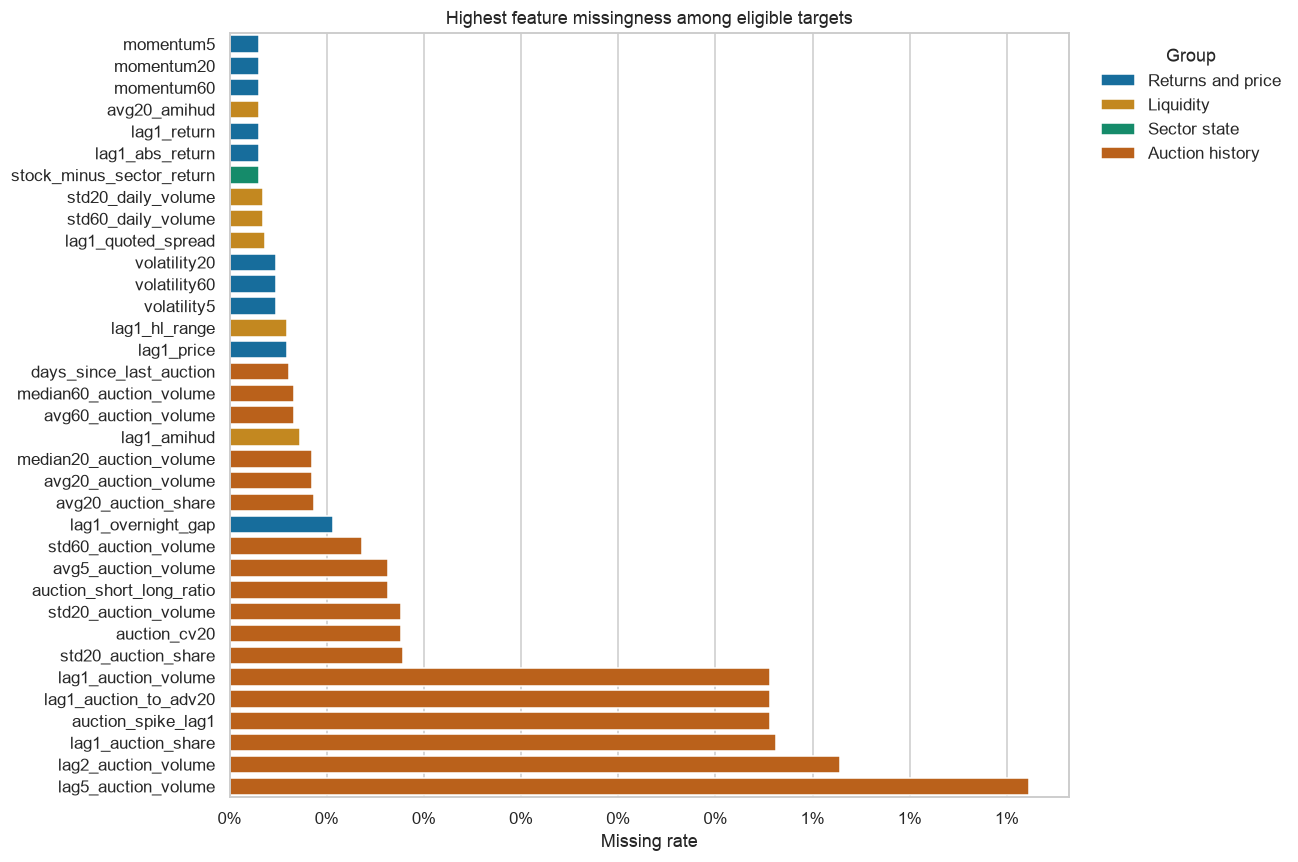

In [5]:
queries = []
for feature in SAFE_FEATURES:
    queries.append(f"""\n        SELECT '{feature}' AS feature,\n               count(*) FILTER (WHERE eligible_target) AS eligible_rows,\n               count(*) FILTER (WHERE eligible_target AND "{feature}" IS NULL) AS missing,\n               count(*) FILTER (WHERE eligible_target AND "{feature}" IS NULL)::DOUBLE\n                   / nullif(count(*) FILTER (WHERE eligible_target), 0) AS missing_rate,\n               count(DISTINCT "{feature}") FILTER (WHERE eligible_target) AS distinct_values\n        FROM engineered\n    """)
missingness = sql(' UNION ALL '.join(queries)).merge(catalog[['variable', 'group']], left_on='feature', right_on='variable', how='left').drop(columns='variable').sort_values('missing_rate', ascending=False)
display(missingness.head(30))
fig, ax = plt.subplots(figsize=(12, 8))
plot_data = missingness.head(35).sort_values('missing_rate')
sns.barplot(data=plot_data, x='missing_rate', y='feature', hue='group', dodge=False, ax=ax)
ax.set(title='Highest feature missingness among eligible targets', xlabel='Missing rate', ylabel='')
ax.xaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
fig.tight_layout()
plt.show()

## Inspect ratios and unstable denominators

In [6]:
ratio_features = ['auction_cv20', 'auction_short_long_ratio', 'lag1_auction_share', 'lag1_auction_to_adv20', 'abnormal_volume_lag1', 'volume_short_long_ratio', 'lag1_turnover', 'lag1_amihud', 'lag1_quoted_spread', 'lag1_hl_range', 'stock_share_sector_volume']
quantile_parts = []
for feature in ratio_features:
    quantile_parts.append(f"\n        SELECT '{feature}' AS feature,\n               min({feature}) AS minimum,\n               approx_quantile({feature}, 0.01) AS p01,\n               approx_quantile({feature}, 0.50) AS median,\n               approx_quantile({feature}, 0.99) AS p99,\n               max({feature}) AS maximum\n        FROM engineered WHERE eligible_target\n    ")
ratio_quantiles = sql(' UNION ALL '.join(quantile_parts))
display(ratio_quantiles)

,feature,minimum,p01,median,p99,maximum
0,auction_cv20,0.0000,0.2404,0.6694,3.3264,4.4301
1,auction_short_long_ratio,0.0001,0.1902,0.9412,2.6749,12.3209
2,lag1_auction_share,0.0000,0.0038,0.0893,0.3948,1.0000
3,lag1_auction_to_adv20,0.0000,0.0029,0.0773,0.6788,15.1131
4,abnormal_volume_lag1,0.0000,0.2513,0.8873,3.4409,19.9723
5,volume_short_long_ratio,0.0000,0.4107,0.9551,2.1297,4.0000
6,lag1_turnover,0.0000,0.0005,0.0068,0.0714,27.2423
7,lag1_amihud,0.0000,0.0000,0.0004,0.2631,152.6268
8,lag1_quoted_spread,0.0000,0.0000,0.0005,0.0159,1.3693
9,lag1_hl_range,0.0000,0.0050,0.0259,0.1502,3.0588


The missingness table describes the entire panel. It is used to understand coverage. Fitting a model later learns its imputation and transformation parameters using only that model's training window. Ratios use `nullif` for zero denominators, preserving undefined values for explicit handling.

## Relationship to auction level and the modelling target

The log auction level captures stock size and general activity. The median-relative log target asks what explains deviations from the stock's historical auction scale. The following common sample shows pooled rank relationships with both, within-stock rank relationships, and the relationship range across years. Correlations are descriptive and can reflect redundant inputs or calendar effects. They guide candidate design and are tested later through chronological forecasts.

,level_Spearman,within_stock_level_rank,residual_Spearman,min_annual_residual_corr,max_annual_residual_corr
feature,,,,,
lag1_auction_volume,0.8822,0.5585,0.0537,0.0330,0.0840
avg5_auction_volume,0.8956,0.5782,0.0246,0.0003,0.0476
median20_auction_volume,0.9208,0.6593,-0.0163,-0.0364,0.0022
std20_auction_volume,0.7778,0.3231,-0.0233,-0.0447,-0.0001
avg20_daily_volume,0.8330,0.4141,0.0024,-0.0221,0.0159
abnormal_volume_lag1,0.1201,0.1170,0.2121,0.1586,0.2817
avg20_turnover,0.2982,0.2736,-0.0127,-0.0346,0.0080
avg20_amihud,-0.6935,-0.2494,-0.0129,-0.0281,0.0129
lag1_quoted_spread,-0.4066,-0.0279,-0.0118,-0.0364,0.0055


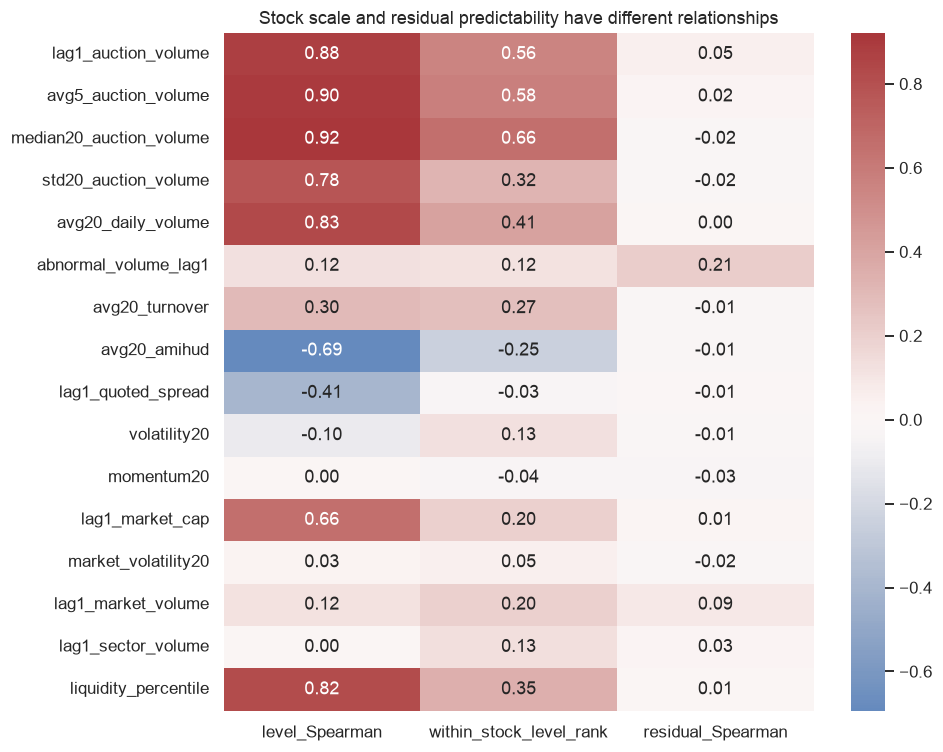

In [7]:
relationships = sql("""
    SELECT date, year, permno, log1p_auction_volume AS target_level,
           log1p_auction_volume - ln(1 + median20_auction_volume) AS target_residual,
           * EXCLUDE(date, year, permno, log1p_auction_volume)
    FROM (SELECT * FROM engineered WHERE eligible_target AND median20_auction_volume > 0)
    USING SAMPLE 150000 ROWS (reservoir, 42)
""")
features = ['lag1_auction_volume', 'avg5_auction_volume', 'median20_auction_volume',
            'std20_auction_volume', 'avg20_daily_volume', 'abnormal_volume_lag1',
            'avg20_turnover', 'avg20_amihud', 'lag1_quoted_spread', 'volatility20',
            'momentum20', 'lag1_market_cap', 'market_volatility20',
            'lag1_market_volume', 'lag1_sector_volume', 'liquidity_percentile']
y = relationships.target_level.rank(pct=True)
r = relationships.target_residual.rank(pct=True)
within_y = y - y.groupby(relationships.permno).transform('mean')
rows = []
for feature in features:
    x = relationships[feature].astype(float).rank(pct=True)
    within_x = x - x.groupby(relationships.permno).transform('mean')
    annual = [g[feature].astype(float).rank().corr(g.target_residual.rank())
              for _, g in relationships.groupby('year')]
    rows.append({'feature': feature, 'level_Spearman': x.corr(y),
                 'within_stock_level_rank': within_x.corr(within_y),
                 'residual_Spearman': x.corr(r),
                 'min_annual_residual_corr': np.nanmin(annual),
                 'max_annual_residual_corr': np.nanmax(annual)})
associations = pd.DataFrame(rows).set_index('feature')
display(associations)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(associations[['level_Spearman', 'within_stock_level_rank', 'residual_Spearman']],
            center=0, cmap='vlag', annot=True, fmt='.2f', ax=ax)
ax.set(title='Stock scale and residual predictability have different relationships', ylabel='')
plt.tight_layout(); plt.show()

## Why transformations were considered

| Transformation | Where used | Rationale |
| --- | --- | --- |
| `log1p(x)` | Highly skewed nonnegative inputs and auction levels | Compress large values and express multiplicative variation more smoothly |
| Ratios | Recent volume relative to a trailing stock-specific level | Separate unusual activity from persistent scale |
| Missing indicators | Inputs missing during historical fitting | Preserve information about absent records or short history |
| Fitted percentile clipping | Continuous inputs at historical 0.5% and 99.5% quantiles | Limit sensitivity to extreme covariate values |
| Median centering and standard-deviation scaling | Continuous model inputs | Make ridge penalties comparable across numerical units |
| Historically fitted categorical encoding | Month and weekday | Represent categories without imposing a numerical slope |

The project's preprocessing helper logs nonnegative features when the ratio of the 99th absolute percentile to median absolute magnitude reaches 20. That is a recorded implementation heuristic. It is fitted anew within each training sample. Forecast clipping at historical 0.1% and 99.9% quantiles is a separate operation applied after reconstruction.

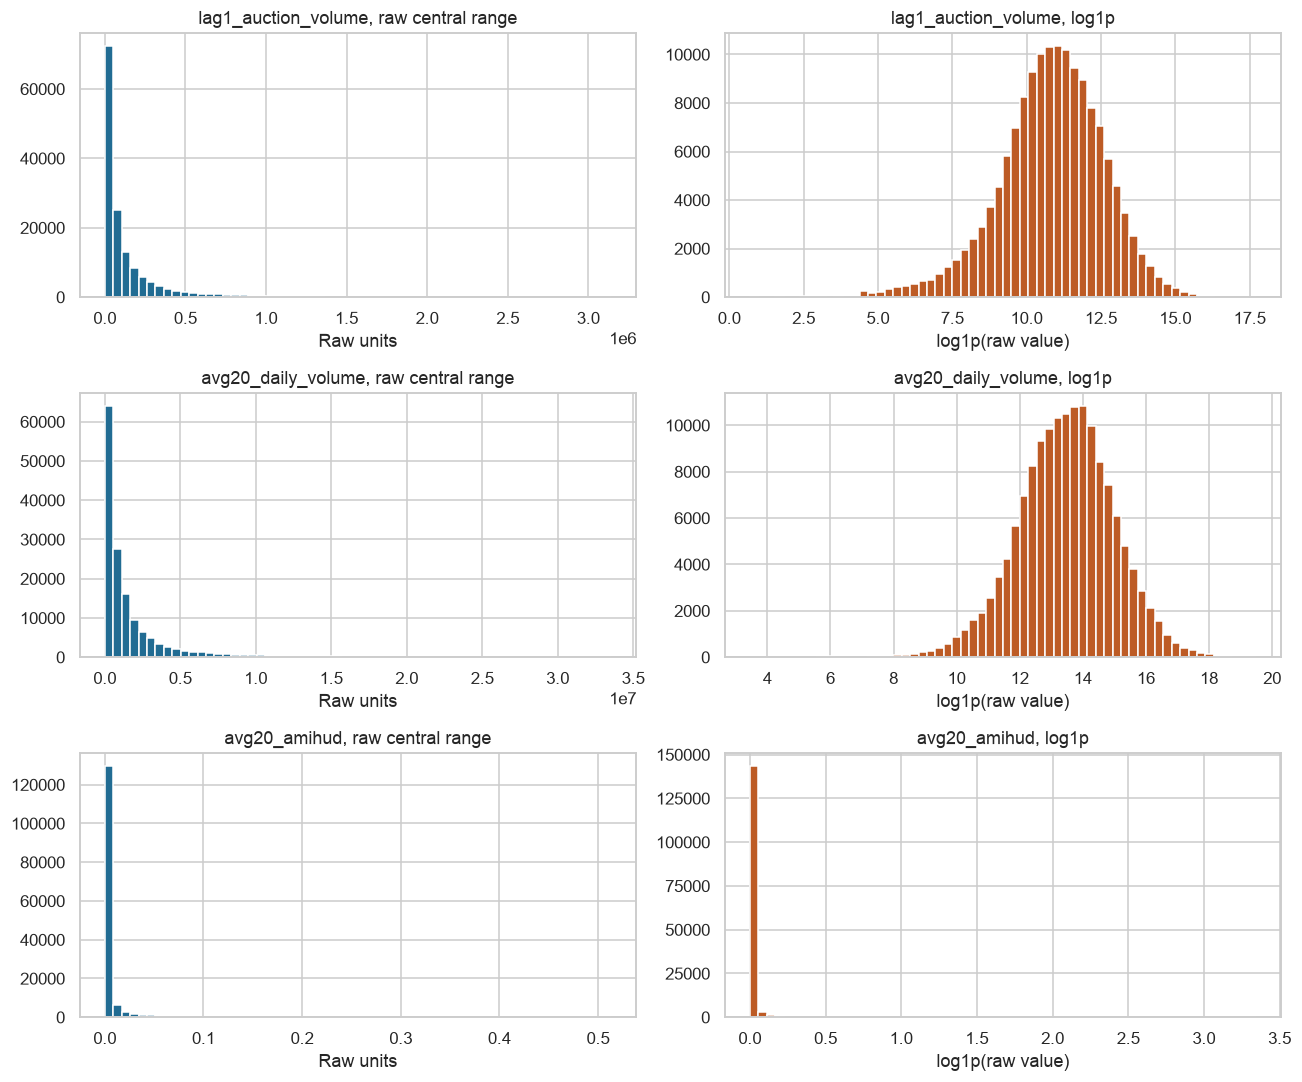

In [8]:
plot_features = ['lag1_auction_volume', 'avg20_daily_volume', 'avg20_amihud']
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for feature, pair in zip(plot_features, axes):
    v = relationships[feature].astype(float).dropna()
    cap = v.quantile(.995)
    pair[0].hist(v[v <= cap], bins=60, color='#216c93')
    pair[0].set(title=f'{feature}, raw central range', xlabel='Raw units')
    pair[1].hist(np.log1p(v.clip(lower=0)), bins=60, color='#bd5b25')
    pair[1].set(title=f'{feature}, log1p', xlabel='log1p(raw value)')
plt.tight_layout(); plt.show()

## Add the three ratio features used by the daily champion

The champion adds logged, smoothed ratios of previous auction to median20, average5 to median20, and previous auction to median60. Each uses quantities already known at the prior close. Explicit ratios give a tree a direct measure of relative activity. Ridge can already represent the difference between two log inputs through its coefficients.

,count,mean,std,min,25%,50%,75%,max
target_residual,"145,852.0000",0.0851,0.6732,-6.5586,-0.3025,0.0016,0.3632,8.0115
ratio_lag1_med20,"145,153.0000",0.0831,0.6420,-6.2497,-0.2739,0.0000,0.3282,7.1935
ratio_avg5_med20,"145,719.0000",0.2383,0.4952,-5.0735,-0.0487,0.1338,0.3963,7.4565
ratio_lag1_med60,"145,153.0000",0.1010,0.6706,-6.1872,-0.2833,0.0089,0.3738,7.3525


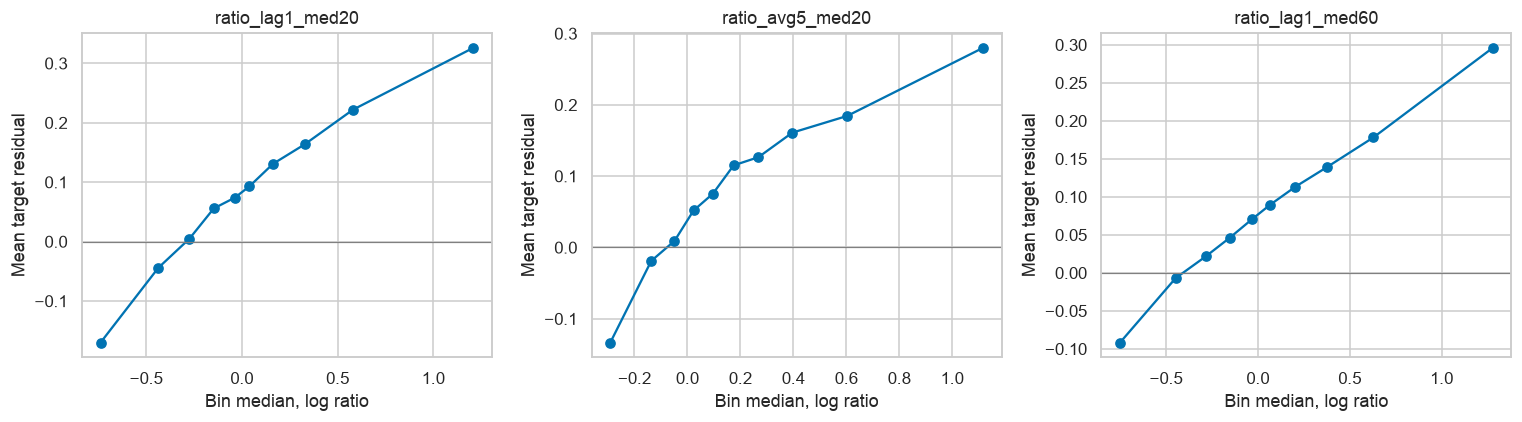

In [9]:
ratio_definitions = {
    'ratio_lag1_med20': 'ln((lag1_auction_volume + 1) / (median20_auction_volume + 1))',
    'ratio_avg5_med20': 'ln((avg5_auction_volume + 1) / (median20_auction_volume + 1))',
    'ratio_lag1_med60': 'ln((lag1_auction_volume + 1) / (median60_auction_volume + 1))',
}
expressions = ', '.join(f'{expression} AS {name}' for name, expression in ratio_definitions.items())
ratio_sample = sql(f"""
    SELECT log1p_auction_volume - ln(1 + median20_auction_volume) AS target_residual,
           {expressions} FROM engineered WHERE eligible_target AND median20_auction_volume > 0
    USING SAMPLE 150000 ROWS (reservoir, 42)
""")
display(ratio_sample.describe().T)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feature, ax in zip(ratio_definitions, axes):
    valid = ratio_sample[[feature, 'target_residual']].dropna().copy()
    valid['bin'] = pd.qcut(valid[feature], 10, duplicates='drop')
    curve = valid.groupby('bin', observed=True).agg(x=(feature, 'median'), y=('target_residual', 'mean'))
    ax.plot(curve.x, curve.y, marker='o')
    ax.axhline(0, color='grey', linewidth=.8)
    ax.set(title=feature, xlabel='Bin median, log ratio', ylabel='Mean target residual')
plt.tight_layout(); plt.show()

## Validate selected historical windows independently

Rebuild the previous auction and trailing 20-row median directly for five stocks with long histories. Removing later rows should leave the earlier history unchanged. This verifies selected equations and their chronology. The source SQL and catalog provide the timing specification for the other feature families.

In [10]:
stock_ids = sql('SELECT permno FROM engineered GROUP BY permno ORDER BY count(*) DESC, permno LIMIT 5').permno.tolist()
stock_list = ','.join(map(str, stock_ids))
rebuilt = sql(f"""
    WITH raw AS (
        SELECT c.date, c.permno, a.auction_volume
        FROM read_parquet('{CRSP}', union_by_name=true) c
        LEFT JOIN read_parquet('{AUCTION}', union_by_name=true) a USING(date, permno)
        WHERE c.permno IN ({stock_list})
    )
    SELECT date, permno,
           lag(auction_volume) OVER (PARTITION BY permno ORDER BY date) AS independent_lag1,
           median(auction_volume) OVER (PARTITION BY permno ORDER BY date
               ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING) AS independent_median20
    FROM raw
""")
actual = sql(f'SELECT date, permno, lag1_auction_volume, median20_auction_volume FROM engineered WHERE permno IN ({stock_list})')
joined = actual.merge(rebuilt, on=['date', 'permno'], validate='one_to_one')
for left, right in [('lag1_auction_volume', 'independent_lag1'),
                    ('median20_auction_volume', 'independent_median20')]:
    np.testing.assert_allclose(joined[left], joined[right], equal_nan=True)
print(f'Independently verified lag1 and median20 on {len(joined):,} stock-days.')

Independently verified lag1 and median20 on 13,830 stock-days.


## Apply historical preprocessing to the engineered features

The demonstration below fits on 2015–2021 and applies the fitted parameters to 2022. It shows the actual transformation decisions and resulting matrix columns for representative predictors. Full ridge and tree experiments will use their specified rolling windows and full feature sets.

In [11]:
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor
train = sql("SELECT * FROM (SELECT * FROM engineered WHERE eligible_target AND year <= 2021) USING SAMPLE 120000 ROWS (reservoir, 42)")
validation = sql("SELECT * FROM (SELECT * FROM engineered WHERE eligible_target AND year = 2022) USING SAMPLE 50000 ROWS (reservoir, 42)")
continuous = ['lag1_auction_volume', 'avg20_daily_volume', 'avg20_amihud', 'volatility20', 'lag1_market_cap']
boolean = ['auction_spike_lag1', 'is_last_trading_day_month']
categorical = ['month', 'day_of_week']
x_train, prep = fit_preprocessor(train, continuous, boolean, categorical)
x_validation = apply_preprocessor(validation, prep, continuous, boolean, categorical)
display(pd.DataFrame(prep['continuous']).T)
display(pd.DataFrame({'matrix_column': prep['output_names'], 'source': prep['output_sources']}))
assert train.date.max() < validation.date.min()
assert np.isfinite(x_train).all() and np.isfinite(x_validation).all()
print(f'Training matrix {x_train.shape}, later matrix {x_validation.shape}.')

,log1p,lower,upper,median,scale,missing_indicator
lag1_auction_volume,True,4.6151,14.8589,10.6542,1.7467,True
avg20_daily_volume,True,8.8758,17.2562,13.4572,1.5068,True
avg20_amihud,True,0.0000,0.4206,0.0006,0.0412,True
volatility20,False,0.0024,0.1231,0.0188,0.0176,True
lag1_market_cap,True,17.4086,26.3160,21.7894,1.7691,True


,matrix_column,source
0,lag1_auction_volume,lag1_auction_volume
1,lag1_auction_volume__missing,lag1_auction_volume
2,avg20_daily_volume,avg20_daily_volume
3,avg20_daily_volume__missing,avg20_daily_volume
4,avg20_amihud,avg20_amihud
5,avg20_amihud__missing,avg20_amihud
6,volatility20,volatility20
7,volatility20__missing,volatility20
8,lag1_market_cap,lag1_market_cap
9,lag1_market_cap__missing,lag1_market_cap


Training matrix (120000, 30), later matrix (50000, 30).


## Checkpoint 1 review

The raw-data audit identifies usable labels and source gaps. The target comparison retains the 20-day-median log residual and carries log growth as the alternative. Feature construction supplies a catalog of 99 sources, plus the three explicit ratios, with historical timing and fitted preprocessing documented.

Review the data exclusions, target rationale, feature definitions and transformation choices before continuing to notebook 04. The remaining planned sequence is listed in notebook 01, including notebook 11 for Kalman filters and related sequential intraday methods after Checkpoint 6.

Construction was adapted from the existing enriched-panel notebook and preprocessing helper. The association tables and figures here were recomputed from raw sources. These descriptive relationships motivate the chronological model comparisons at the next checkpoint.

In [12]:
assert len(SAFE_FEATURES) == 99
assert len(ratio_definitions) == 3
print('Checkpoint 1 validation complete.')
con.close()
work.cleanup()

Checkpoint 1 validation complete.
